# Phase 1: Data Understanding and Descriptive Statistics

## Data Source and Collection (Task 1)

This project uses data from the National Health and Nutrition Examination Survey (NHANES), conducted by the National Center for Health Statistics (NCHS), part of the Centers for Disease Control and Prevention (CDC).

The selected dataset covers August 2021 to August 2023. NHANES is a nationally representative, cross-sectional survey designed to assess the health and nutritional status of the U.S. civilian, noninstitutionalized population.

NHANES uses a complex, multistage probability sampling design involving stratification and clustering. Data are collected through household interviews, health examinations, and questionnaires administered at Mobile Examination Centers (MECs).

Two publicly available files are used in this project:

- **DEMO_L.xpt:** Contains demographic information, including age, gender, education, income, and survey design variables.
- **DPQ_L.xpt:** Contains responses to the Patient Health Questionnaire (PHQ-9), used to assess depressive symptoms during the previous two weeks. These questions were administered through an audio computer-assisted self-interview system (ACASI).

This is an observational study, not a randomized experiment. Participants were not randomly assigned to education levels, and no intervention was applied. Therefore, the analysis can examine associations but cannot establish causality.

The data files used here are publicly accessible. However, the public DPQ file includes only adults aged 18 and older, and this project further restricts the analysis to participants aged 20 and older. Nonresponse, missing values, and the complex survey design may affect the interpretation and generalizability of the results.

### Official Sources

- [NHANES 2021–2023 Overview](https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/default.aspx?Cycle=2021-2023)
- [Demographics Documentation (DEMO_L)](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm)
- [Depression Screener Documentation (DPQ_L)](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DPQ_L.htm)

## 1. Data Loading

This section loads the NHANES demographic and depression datasets.

In [2]:
demo = pd.read_sas( demo_path, format="xport")
dpq = pd.read_sas(dpq_path,format="xport")

NameError: name 'pd' is not defined

In [ ]:
print("DEMO dataset:", demo.shape)
print("DPQ dataset:", dpq.shape)

DEMO dataset: (11933, 27)
DPQ dataset: (6337, 11)


In [ ]:
print("DEMO columns:")
print(demo.columns.tolist())

print("\nDPQ columns:")
print(dpq.columns.tolist())

DEMO columns:
['SEQN', 'SDDSRVYR', 'RIDSTATR', 'RIAGENDR', 'RIDAGEYR', 'RIDAGEMN', 'RIDRETH1', 'RIDRETH3', 'RIDEXMON', 'RIDEXAGM', 'DMQMILIZ', 'DMDBORN4', 'DMDYRUSR', 'DMDEDUC2', 'DMDMARTZ', 'RIDEXPRG', 'DMDHHSIZ', 'DMDHRGND', 'DMDHRAGZ', 'DMDHREDZ', 'DMDHRMAZ', 'DMDHSEDZ', 'WTINT2YR', 'WTMEC2YR', 'SDMVSTRA', 'SDMVPSU', 'INDFMPIR']

DPQ columns:
['SEQN', 'DPQ010', 'DPQ020', 'DPQ030', 'DPQ040', 'DPQ050', 'DPQ060', 'DPQ070', 'DPQ080', 'DPQ090', 'DPQ100']


In [ ]:
display(demo.head())

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,50055.450807,54374.463898,173.0,2.0,5.00
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,29087.450605,34084.721548,173.0,2.0,5.00
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,80062.674301,81196.277992,174.0,1.0,1.41
3,130381.0,12.0,2.0,2.0,5.0,NaN,5.0,7.0,1.0,71.0,...,2.0,2.0,2.0,3.0,NaN,38807.268902,55698.607106,182.0,2.0,1.53
4,130382.0,12.0,2.0,1.0,2.0,NaN,3.0,3.0,2.0,34.0,...,2.0,2.0,3.0,1.0,2.0,30607.519774,36434.146346,182.0,2.0,3.60


In [ ]:
display(dpq.head())

,SEQN,DPQ010,DPQ020,DPQ030,DPQ040,DPQ050,DPQ060,DPQ070,DPQ080,DPQ090,DPQ100
0,130378.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,130379.0,5.397605e-79,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
2,130380.0,5.397605e-79,5.397605e-79,1.000000e+00,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
3,130386.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,1.000000e+00,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79
4,130387.0,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,5.397605e-79,NaN


In [ ]:
print("DEMO information:")
demo.info()

print("\nDPQ information:")
dpq.info()

DEMO information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11933 entries, 0 to 11932
Data columns (total 27 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SEQN      11933 non-null  float64
 1   SDDSRVYR  11933 non-null  float64
 2   RIDSTATR  11933 non-null  float64
 3   RIAGENDR  11933 non-null  float64
 4   RIDAGEYR  11933 non-null  float64
 5   RIDAGEMN  377 non-null    float64
 6   RIDRETH1  11933 non-null  float64
 7   RIDRETH3  11933 non-null  float64
 8   RIDEXMON  8860 non-null   float64
 9   RIDEXAGM  2787 non-null   float64
 10  DMQMILIZ  8301 non-null   float64
 11  DMDBORN4  11914 non-null  float64
 12  DMDYRUSR  1875 non-null   float64
 13  DMDEDUC2  7794 non-null   float64
 14  DMDMARTZ  7792 non-null   float64
 15  RIDEXPRG  1503 non-null   float64
 16  DMDHHSIZ  11933 non-null  float64
 17  DMDHRGND  4115 non-null   float64
 18  DMDHRAGZ  4124 non-null   float64
 19  DMDHREDZ  3746 non-null   float64
 20  DMDHRMAZ  

In [ ]:
print("DEMO unique SEQN:", demo["SEQN"].is_unique)
print("DPQ unique SEQN:", dpq["SEQN"].is_unique)

print("DEMO duplicated IDs:", demo["SEQN"].duplicated().sum())
print("DPQ duplicated IDs:", dpq["SEQN"].duplicated().sum())

DEMO unique SEQN: True
DPQ unique SEQN: True
DEMO duplicated IDs: 0
DPQ duplicated IDs: 0


In [ ]:
dpq_items = [f"DPQ{i:03d}" for i in range(10, 100, 10)]
dpq_columns = dpq_items + ["DPQ100"]
xport_zero = 5.397605346934028e-79
print("Incorrect zero representations:")
print((dpq[dpq_columns] == xport_zero).sum())
dpq[dpq_columns] = dpq[dpq_columns].replace(xport_zero, 0.)
print("\nValues after correction:")

for col in dpq_columns:
    print(col, sorted(dpq[col].dropna().unique()))

Incorrect zero representations:
DPQ010    3703
DPQ020    3674
DPQ030    2772
DPQ040    2348
DPQ050    3710
DPQ060    3971
DPQ070    4036
DPQ080    4748
DPQ090    5207
DPQ100    2573
dtype: int64

Values after correction:
DPQ010 [0.0, 1.0, 2.0, 3.0, 7.0, 9.0]
DPQ020 [0.0, 1.0, 2.0, 3.0, 7.0, 9.0]
DPQ030 [0.0, 1.0, 2.0, 3.0, 7.0, 9.0]
DPQ040 [0.0, 1.0, 2.0, 3.0, 7.0, 9.0]
DPQ050 [0.0, 1.0, 2.0, 3.0, 9.0]
DPQ060 [0.0, 1.0, 2.0, 3.0, 7.0, 9.0]
DPQ070 [0.0, 1.0, 2.0, 3.0, 7.0, 9.0]
DPQ080 [0.0, 1.0, 2.0, 3.0, 7.0, 9.0]
DPQ090 [0.0, 1.0, 2.0, 3.0, 9.0]
DPQ100 [0.0, 1.0, 2.0, 3.0, 7.0, 9.0]


In [ ]:
dpq_items = [f"DPQ{i:03d}" for i in range(10, 100, 10)]
dpq_columns = dpq_items + ["DPQ100"]
response_codes = [0, 1, 2, 3, 7, 9]
rows = []
for col in dpq_columns:
    counts = dpq[col].value_counts()
    for code in response_codes:
        rows.append({"Variable": col, "Response": code, "Count": counts.get(code, 0)})
    rows.append({"Variable": col, "Response": "Missing", "Count": dpq[col].isna().sum()})
frequency_table = pd.DataFrame(rows)
frequency_table["Percentage"] = (frequency_table["Count"] / len(dpq) * 100).round(2)
display(frequency_table)

,Variable,Response,Count,Percentage
0,DPQ010,0,3703,58.43
1,DPQ010,1,1205,19.02
2,DPQ010,2,334,5.27
3,DPQ010,3,256,4.04
4,DPQ010,7,5,0.08
...,...,...,...,...
65,DPQ100,2,207,3.27
66,DPQ100,3,74,1.17
67,DPQ100,7,4,0.06
68,DPQ100,9,3,0.05


In [ ]:
frequency_wide = frequency_table.pivot(index="Variable", columns="Response", values="Count")
frequency_wide = frequency_wide.reindex(columns=[0, 1, 2, 3, 7, 9, "Missing"])
frequency_wide = frequency_wide.fillna(0).astype(int)
display(frequency_wide)

Response,0,1,2,3,7,9,Missing
Variable,,,,,,,
DPQ010,3703,1205,334,256,5,16,818
DPQ020,3674,1325,295,214,3,7,819
DPQ030,2772,1690,511,536,3,4,821
DPQ040,2348,2113,571,474,3,5,823
DPQ050,3710,1138,371,291,0,3,824
DPQ060,3971,1054,268,212,3,2,827
DPQ070,4036,989,277,203,2,1,829
DPQ080,4748,511,129,108,4,8,829
DPQ090,5207,209,57,28,0,5,831


### Data Quality Decisions

1. The XPORT zero-reading artifact was corrected.
2. Response codes 0, 1, 2, and 3 are treated as valid PHQ-9 responses.
3. Codes 7 (Refused) and 9 (Don't know) are treated as invalid for score calculation.
4. Missing values are not replaced with zero.
5. DPQ100 is excluded from the PHQ-9 total score because it is a supplementary functional impairment question.
6. A valid PHQ-9 total score requires all nine symptom items to be available.

In [ ]:
dpq_clean = dpq.copy()
dpq_clean[dpq_items] = dpq_clean[dpq_items].replace({7: np.nan, 9: np.nan})
print("Original dataset shape:", dpq.shape)
print("Clean dataset shape:", dpq_clean.shape)

Original dataset shape: (6337, 11)
Clean dataset shape: (6337, 11)


In [ ]:
valid_items_per_person = dpq_clean[dpq_items].notna().sum(axis=1)
completeness_table = (
    valid_items_per_person
    .value_counts()
    .reindex(range(10), fill_value=0)
    .sort_index()
    .rename_axis("Valid_Responses")
    .reset_index(name="Participants")
)
completeness_table["Percentage"] = (
    completeness_table["Participants"] / len(dpq_clean) * 100
).round(2)
display(completeness_table)

,Valid_Responses,Participants,Percentage
0,0,818,12.91
1,1,1,0.02
2,2,2,0.03
3,3,2,0.03
4,4,2,0.03
5,5,5,0.08
6,6,4,0.06
7,7,9,0.14
8,8,39,0.62
9,9,5455,86.08


In [ ]:
complete_phq9_mask = dpq_clean[dpq_items].notna().all(axis=1)
complete_count = complete_phq9_mask.sum()
print("Total participants:", len(dpq_clean))
print("Complete PHQ-9 responses:", complete_count)
print("Complete percentage:", round(complete_count / len(dpq_clean) * 100, 2), "%")

Total participants: 6337
Complete PHQ-9 responses: 5455
Complete percentage: 86.08 %


### PHQ-9 Questionnaire Completeness

Among 6,337 participants in the DPQ dataset:

- 5,455 participants (86.08%) had all nine valid responses.
- 64 participants (1.01%) had between one and eight valid responses.
- 818 participants (12.91%) had no valid responses.

A complete PHQ-9 score requires valid responses to all nine symptom items.

Participants with incomplete responses are not assigned a total score at this stage.

In [ ]:
merged_check = demo.merge(
    dpq_clean,
    on="SEQN",
    how="outer",
    validate="one_to_one",
    indicator=True
)
print("Merged shape:", merged_check.shape)
print("\nMerge results:")
print(merged_check["_merge"].value_counts())
print("\nUnique SEQN:", merged_check["SEQN"].is_unique)

Merged shape: (11933, 38)

Merge results:
_merge
both          6337
left_only     5596
right_only       0
Name: count, dtype: int64

Unique SEQN: True


In [ ]:
merged = demo.merge(
    dpq_clean,
    on="SEQN",
    how="inner",
    validate="one_to_one"
)
print("Merged dataset shape:", merged.shape)
print("Unique participants:", merged["SEQN"].nunique())
print("Duplicated participants:", merged["SEQN"].duplicated().sum())
print("\nFirst five records:")
display(merged.head())

Merged dataset shape: (6337, 37)
Unique participants: 6337
Duplicated participants: 0

First five records:


,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DPQ010,DPQ020,DPQ030,DPQ040,DPQ050,DPQ060,DPQ070,DPQ080,DPQ090,DPQ100
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,130386.0,12.0,2.0,1.0,34.0,NaN,1.0,1.0,1.0,NaN,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
4,130387.0,12.0,2.0,2.0,68.0,NaN,3.0,3.0,2.0,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN


### Task 2: Observation Unit and Data Structure

The unit of observation in this project is an individual NHANES participant. Each row represents one participant, uniquely identified by the variable `SEQN`.

The demographic dataset (DEMO) contains 11,933 participants, while the depression questionnaire dataset (DPQ) contains 6,337 participants.

Both datasets were checked for duplicate participant identifiers. No duplicate `SEQN` values were found in either dataset.

The datasets were merged using an inner join on `SEQN`, with a one-to-one relationship enforced using `validate="one_to_one"`.

The merged dataset contains 6,337 unique participants, with no duplicated identifiers. A total of 5,596 participants from the demographic dataset did not have a matching DPQ record.

Each participant contributes one row to the merged dataset. There are no repeated observations of the same participant in these files.

Although NHANES uses a stratified and clustered sampling design, this does not mean that participants have repeated measurements in the current analytical dataset.

The merged dataset is further restricted to adults aged 20 years and older, followed by additional data-quality and completeness requirements.

### Task 3: Sampling, Selection, and Generalizability

NHANES uses a complex, multistage probability sampling design with stratification and clustering. Participants are selected through a probability-based process rather than simple random sampling.

The study is observational and cross-sectional. Although participants are selected through probability sampling, they are not randomly assigned to education levels. Therefore, any observed relationship between educational attainment and depressive symptoms should be interpreted as an association rather than a causal effect.

The NHANES sampling design aims to produce estimates representative of the U.S. civilian, noninstitutionalized population. In this project, the target population is restricted to adults aged 20 years and older.

Survey sampling weights are important because participants have different probabilities of selection and response. Using appropriate weights helps produce population-level estimates.

However, the analytical sample is further restricted to participants with valid education information and complete PHQ-9 responses. The adjusted analysis also requires non-missing age, gender, and income information.

These exclusions may introduce selection bias and affect generalizability. Furthermore, ignoring survey weights, stratification, or clustering can lead to misleading statistical estimates or uncertainty measures.

Consequently, results should be interpreted with attention to the NHANES sampling design, missing data, and the observational nature of the study.

### Task 4: Variable Classification and Measurement Scales

The main variables in this study are classified according to their measurement scales and their roles in the statistical analysis.

| Variable | Description | Measurement Scale | Role |
|---|---|---|---|
| SEQN | Participant identifier | Nominal | Unique identifier |
| DMDEDUC2_clean | Educational attainment (5 levels) | Ordinal categorical | Main explanatory variable |
| phq9_positive | Positive PHQ-9 screening (0/1) | Binary categorical | Response variable |
| phq9_total | PHQ-9 total score (0–27) | Discrete quantitative | Secondary outcome |
| RIDAGEYR | Age in years | Discrete quantitative | Adjustment variable |
| RIAGENDR | Gender recorded in NHANES | Nominal categorical | Adjustment variable |
| INDFMPIR | Family income-to-poverty ratio | Quantitative | Adjustment variable |
| DPQ010–DPQ090 | Individual PHQ-9 responses (0–3) | Ordinal categorical | Components of PHQ-9 score |
| WTMEC2YR | MEC examination sampling weight | Quantitative | Survey weight |
| SDMVSTRA | Masked sampling stratum | Nominal categorical | Survey design variable |
| SDMVPSU | Masked primary sampling unit | Nominal categorical | Survey design variable |

#### Choice of Statistical Summaries

Categorical variables, including education level, gender, and positive PHQ-9 screening, are summarized using frequency tables and percentages. Bar charts are suitable for visualizing their distributions.

Quantitative variables, including age, income-to-poverty ratio, and PHQ-9 total score, are summarized using the mean, median, standard deviation, quartiles, and interquartile range (IQR), where appropriate.

Histograms are used to examine the distributions of quantitative variables.

Educational attainment is an ordinal variable because its categories have a meaningful order. However, equal numerical differences between education codes do not represent equal differences in educational attainment.

The PHQ-9 total score is a discrete quantitative variable, while positive PHQ-9 screening is binary, defined using a threshold of 10.

Survey weights and design variables are used to account for the complex NHANES sampling design. They are not treated as ordinary explanatory variables.

This classification guides the selection of descriptive statistics, visualizations, and statistical methods in later phases.

In [ ]:
print("Minimum age:", merged["RIDAGEYR"].min())
print("Maximum age:", merged["RIDAGEYR"].max())

print("\nAge distribution:")
display( merged["RIDAGEYR"].describe())

Minimum age: 18.0
Maximum age: 80.0

Age distribution:


count    6337.000000
mean       52.325548
std        18.280888
min        18.000000
25%        37.000000
50%        56.000000
75%        67.000000
max        80.000000
Name: RIDAGEYR, dtype: float64

In [ ]:
print("Participants under 20:", (merged["RIDAGEYR"] < 20).sum())
print("Participants aged 20 or older:", (merged["RIDAGEYR"] >= 20).sum())

Participants under 20: 273
Participants aged 20 or older: 6064


In [ ]:
analysis_base = merged.loc[merged["RIDAGEYR"] >= 20].copy()
print("Original merged dataset:", merged.shape)
print("Adult analytical dataset:", analysis_base.shape)
print("Minimum age:", analysis_base["RIDAGEYR"].min())
print("Participants:", len(analysis_base))

Original merged dataset: (6337, 37)
Adult analytical dataset: (6064, 37)
Minimum age: 20.0
Participants: 6064


In [ ]:
print("Education distribution:")
display(analysis_base["DMDEDUC2"].value_counts(dropna=False).sort_index())
print("\nGender distribution:")
display(analysis_base["RIAGENDR"].value_counts(dropna=False).sort_index())
print("\nIncome-to-poverty ratio:")
display(analysis_base["INDFMPIR"].describe())

Education distribution:


DMDEDUC2
1.0     292
2.0     482
3.0    1297
4.0    1846
5.0    2143
9.0       4
Name: count, dtype: int64


Gender distribution:


RIAGENDR
1.0    2720
2.0    3344
Name: count, dtype: int64


Income-to-poverty ratio:


count    5.272000e+03
mean     2.920036e+00
std      1.655077e+00
min      5.397605e-79
25%      1.410000e+00
50%      2.820000e+00
75%      5.000000e+00
max      5.000000e+00
Name: INDFMPIR, dtype: float64

In [ ]:
variables = ["DMDEDUC2", "RIAGENDR", "INDFMPIR"]
missing_summary = pd.DataFrame({
    "Missing_Count": analysis_base[variables].isna().sum(),
    "Missing_Percentage": (
        analysis_base[variables].isna().mean() * 100
    ).round(2)
})
display(missing_summary)

,Missing_Count,Missing_Percentage
DMDEDUC2,0,0.00
RIAGENDR,0,0.00
INDFMPIR,792,13.06


In [ ]:
xport_zero = 5.397605346934028e-79
demo_artifacts = (demo == xport_zero).sum()
print("Affected DEMO columns:")
display(demo_artifacts[demo_artifacts > 0])
demo_clean = demo.replace(xport_zero, 0.0)
dpq_clean = dpq.replace(xport_zero, 0.0)
dpq_clean[dpq_items] = dpq_clean[dpq_items].replace({7: np.nan, 9: np.nan})
print("\nDEMO artifact count after correction:", (demo_clean == xport_zero).sum().sum())
print("DPQ artifact count after correction:", (dpq_clean == xport_zero).sum().sum())

Affected DEMO columns:


RIDAGEYR     189
RIDAGEMN      17
RIDEXAGM       4
WTMEC2YR    3073
INDFMPIR     100
dtype: int64


DEMO artifact count after correction: 0
DPQ artifact count after correction: 0


In [ ]:
merged = demo_clean.merge(
    dpq_clean,
    on="SEQN",
    how="inner",
    validate="one_to_one"
)
analysis_base = merged.loc[merged["RIDAGEYR"] >= 20].copy()
print("Merged dataset:", merged.shape)
print("Adult dataset:", analysis_base.shape)

Merged dataset: (6337, 37)
Adult dataset: (6064, 37)


In [ ]:
analysis_base["DMDEDUC2_clean"] = (
    analysis_base["DMDEDUC2"].replace({
        7: np.nan,
        9: np.nan
    })
)
print("Education after recoding:")
display(
    analysis_base["DMDEDUC2_clean"]
    .value_counts(dropna=False)
    .sort_index()
)

Education after recoding:


DMDEDUC2_clean
1.0     292
2.0     482
3.0    1297
4.0    1846
5.0    2143
NaN       4
Name: count, dtype: int64

In [ ]:
print("Income-to-poverty ratio after correction:")
display(analysis_base["INDFMPIR"].describe())
print("\nValid zero values:", (analysis_base["INDFMPIR"] == 0).sum())
print("Missing income:", analysis_base["INDFMPIR"].isna().sum())

Income-to-poverty ratio after correction:


count    5272.000000
mean        2.920036
std         1.655077
min         0.000000
25%         1.410000
50%         2.820000
75%         5.000000
max         5.000000
Name: INDFMPIR, dtype: float64


Valid zero values: 52
Missing income: 792


In [ ]:
allowed_values = {0.0, 1.0, 2.0, 3.0}
unexpected_values = {}
for col in dpq_items:
    actual_values = set(analysis_base[col].dropna().unique())
    unexpected = actual_values - allowed_values
    if unexpected:
        unexpected_values[col] = unexpected
print("Unexpected values:")
print(unexpected_values)

Unexpected values:
{}


In [ ]:
analysis_base["phq9_n_valid"] = analysis_base[dpq_items].notna().sum(axis=1)
analysis_base["phq9_complete"] = analysis_base["phq9_n_valid"] == 9
complete_count = analysis_base["phq9_complete"].sum()
print("Total adults:", len(analysis_base))
print("Complete PHQ-9:", complete_count)
print("Incomplete PHQ-9:", len(analysis_base) - complete_count)
print("Complete percentage:",  round(complete_count / len(analysis_base) * 100, 2),  "%")

Total adults: 6064
Complete PHQ-9: 5210
Incomplete PHQ-9: 854
Complete percentage: 85.92 %


In [ ]:
print("WTMEC2YR summary:")
display(analysis_base["WTMEC2YR"].describe())
print("Zero weights:", (analysis_base["WTMEC2YR"] == 0).sum())
print("Missing weights:", analysis_base["WTMEC2YR"].isna().sum())

WTMEC2YR summary:


count      6064.000000
mean      40412.461880
std       29311.802337
min        4581.595095
25%       20169.578530
50%       31816.894080
75%       50177.111770
max      227108.296958
Name: WTMEC2YR, dtype: float64

Zero weights: 0
Missing weights: 0


In [ ]:
analysis_base["phq9_total"] = (
    analysis_base[dpq_items].sum(
        axis=1,
        min_count=9
    )
)
print("Available PHQ-9 scores:",
      analysis_base["phq9_total"].notna().sum())
print("Missing PHQ-9 scores:",
      analysis_base["phq9_total"].isna().sum())
print("Minimum score:",
      analysis_base["phq9_total"].min())
print("Maximum score:",
      analysis_base["phq9_total"].max())

Available PHQ-9 scores: 5210
Missing PHQ-9 scores: 854
Minimum score: 0.0
Maximum score: 26.0


In [ ]:
analysis_base["phq9_positive"] = pd.Series(
    pd.NA,
    index=analysis_base.index,
    dtype="Int64"
)
valid_scores = analysis_base["phq9_total"].notna()
analysis_base.loc[valid_scores, "phq9_positive"] = (
    analysis_base.loc[valid_scores, "phq9_total"] >= 10
).astype("int64")

In [ ]:
print("PHQ-9 screening results:")
display(
    analysis_base["phq9_positive"]
    .value_counts(dropna=False)
    .sort_index()
)
print("\nScreening percentages among valid scores:")
display(
    analysis_base.loc[
        valid_scores,
        "phq9_positive"
    ].value_counts(normalize=True).mul(100).round(2)
)

PHQ-9 screening results:


phq9_positive
0       4549
1        661
<NA>     854
Name: count, dtype: Int64


Screening percentages among valid scores:


phq9_positive
0    87.31
1    12.69
Name: proportion, dtype: Float64

In [ ]:
education_labels = {
    1: "Less than 9th grade",
    2: "9-11th grade",
    3: "High school graduate/GED",
    4: "Some college/AA degree",
    5: "College graduate or above"
}
edu_analysis = analysis_base.loc[
    analysis_base["phq9_positive"].notna()
    & analysis_base["DMDEDUC2_clean"].notna()
].copy()
edu_analysis["education_group"] = pd.Categorical(
    edu_analysis["DMDEDUC2_clean"].map(education_labels),
    categories=list(education_labels.values()),
    ordered=True
)
education_summary = (
    edu_analysis.groupby("education_group", observed=True)
    .agg(
        Participants=("phq9_positive", "size"),
        Positive=("phq9_positive", "sum")
    )
)
education_summary["Negative"] = (
    education_summary["Participants"]
    - education_summary["Positive"]
)
education_summary["Positive_Percentage"] = (
    education_summary["Positive"]
    / education_summary["Participants"]
    * 100
).round(2)
display(education_summary)
print("\nTotal participants:", len(edu_analysis))

,Participants,Positive,Negative,Positive_Percentage
education_group,,,,
Less than 9th grade,176,35,141,19.89
9-11th grade,372,61,311,16.4
High school graduate/GED,1071,165,906,15.41
Some college/AA degree,1622,245,1377,15.1
College graduate or above,1967,154,1813,7.83



Total participants: 5208


In [ ]:
weighted_edu = edu_analysis.assign(
    weighted_positive=(
        edu_analysis["phq9_positive"]
        * edu_analysis["WTMEC2YR"]
    )
)
weighted_summary = (
    weighted_edu
    .groupby("education_group", observed=True)
    .agg(
        Participants=("phq9_positive", "size"),
        Positive=("phq9_positive", "sum"),
        Total_Weight=("WTMEC2YR", "sum"),
        Positive_Weight=("weighted_positive", "sum")
    )
)
weighted_summary["Unweighted_Percentage"] = (
    weighted_summary["Positive"]
    / weighted_summary["Participants"]
    * 100
).round(2)
weighted_summary["Weighted_Percentage"] = (
    weighted_summary["Positive_Weight"]
    / weighted_summary["Total_Weight"]
    * 100
).round(2)
display(weighted_summary)

,Participants,Positive,Total_Weight,Positive_Weight,Unweighted_Percentage,Weighted_Percentage
education_group,,,,,,
Less than 9th grade,176,35,5.551936e+06,981426.800372,19.89,17.68
9-11th grade,372,61,1.237994e+07,1983655.736133,16.4,16.02
High school graduate/GED,1071,165,5.420963e+07,7769398.642789,15.41,14.33
Some college/AA degree,1622,245,6.399247e+07,8720212.530468,15.1,13.63
College graduate or above,1967,154,7.523692e+07,6309591.864949,7.83,8.39


In [ ]:
print("Total participants:", len(edu_analysis))
print(
    "Missing income:",
    edu_analysis["INDFMPIR"].isna().sum()
)
print(
    "Missing income percentage:",
    round(
        edu_analysis["INDFMPIR"].isna().mean() * 100,
        2
    ),
    "%"
)

Total participants: 5208
Missing income: 624
Missing income percentage: 11.98 %


In [ ]:
income_missing_analysis = edu_analysis.copy()
income_missing_analysis["income_missing"] = (
    income_missing_analysis["INDFMPIR"].isna()
)
income_missing_summary = (
    income_missing_analysis
    .groupby(
        ["education_group", "phq9_positive"],
        observed=True
    )
    .agg(
        Participants=("SEQN", "size"),
        Missing_Income=("income_missing", "sum")
    )
)
income_missing_summary["Missing_Percentage"] = (
    income_missing_summary["Missing_Income"]
    / income_missing_summary["Participants"]
    * 100
).round(2)
display(income_missing_summary)

Participants  Missing_Income  \
education_group           phq9_positive                                 
Less than 9th grade       0                       141              27   
                          1                        35               7   
9-11th grade              0                       311              47   
                          1                        61               7   
High school graduate/GED  0                       906             134   
                          1                       165              16   
Some college/AA degree    0                      1377             170   
                          1                       245              22   
College graduate or above 0                      1813             179   
                          1                       154              15   

                                         Missing_Percentage  
education_group           phq9_positive                      
Less than 9th grade       0                           19.15  
                          1                           20.00  
9-11th grade              0                           15.11  
                          1                           11.48  
High school graduate/GED  0                           14.79  
                          1                            9.70  
Some college/AA degree    0                           12.35  
                          1                            8.98  
College graduate or above 0                            9.87  
                          1                            9.74

In [ ]:
edu_analysis["income_status"] = np.where(
    edu_analysis["INDFMPIR"].isna(),
    "Missing",
    "Available"
)
income_profile = (
    edu_analysis
    .groupby("income_status")
    .agg(
        Participants=("SEQN", "size"),
        Mean_Age=("RIDAGEYR", "mean"),
        Median_Age=("RIDAGEYR", "median"),
        Female_Percentage=(
            "RIAGENDR",
            lambda x: (x == 2).mean() * 100
        ),
        Positive_Screening_Percentage=(
            "phq9_positive",
            "mean"
        )
    )
)
income_profile["Positive_Screening_Percentage"] *= 100
display(income_profile.round(2))

,Participants,Mean_Age,Median_Age,Female_Percentage,Positive_Screening_Percentage
income_status,,,,,
Available,4584,53.75,58.0,54.89,12.94
Missing,624,53.54,58.0,52.72,10.74


In [ ]:
education_by_income = pd.crosstab(
    edu_analysis["education_group"],
    edu_analysis["income_status"],
    normalize="columns"
) * 100
display(education_by_income.round(2))

income_status,Available,Missing
education_group,,
Less than 9th grade,3.10,5.45
9-11th grade,6.94,8.65
High school graduate/GED,20.09,24.04
Some college/AA degree,31.20,30.77
College graduate or above,38.68,31.09


In [ ]:
model_variables = [
    "phq9_positive",
    "education_group",
    "RIDAGEYR",
    "RIAGENDR",
    "INDFMPIR",
    "WTMEC2YR",
    "SDMVSTRA",
    "SDMVPSU"
]
model_missingness = pd.DataFrame({
    "Available": edu_analysis[model_variables].notna().sum(),
    "Missing": edu_analysis[model_variables].isna().sum(),
    "Missing_Percentage": (
        edu_analysis[model_variables].isna().mean() * 100
    )
})
display(model_missingness.round(2))

,Available,Missing,Missing_Percentage
phq9_positive,5208,0,0.00
education_group,5208,0,0.00
RIDAGEYR,5208,0,0.00
RIAGENDR,5208,0,0.00
INDFMPIR,4584,624,11.98
WTMEC2YR,5208,0,0.00
SDMVSTRA,5208,0,0.00
SDMVPSU,5208,0,0.00


In [ ]:
model_cc = edu_analysis.dropna(
    subset=model_variables
).copy()
print("Original analytical sample:", len(edu_analysis))
print("Complete-case model sample:", len(model_cc))
print("Excluded participants:", len(edu_analysis) - len(model_cc))
print(
    "Complete-case percentage:",
    round(len(model_cc) / len(edu_analysis) * 100, 2),
    "%"
)

Original analytical sample: 5208
Complete-case model sample: 4584
Excluded participants: 624
Complete-case percentage: 88.02 %


In [ ]:
audit_vars = [
    "DMDEDUC2_clean", "RIAGENDR", "RIDAGEYR",
    "INDFMPIR", "phq9_total", "WTMEC2YR",
    "SDMVSTRA", "SDMVPSU"
]
missing_audit = pd.DataFrame({
    "Missing": analysis_base[audit_vars].isna().sum(),
    "Missing_Percent": analysis_base[audit_vars].isna().mean() * 100
})
display(missing_audit.round(2))

valid_scores = analysis_base["phq9_total"].notna()

quality_checks = {
    "Duplicate SEQN": analysis_base["SEQN"].duplicated().sum(),
    "Invalid age": (~analysis_base["RIDAGEYR"].between(20, 80)).sum(),
    "Invalid education": (
        analysis_base["DMDEDUC2_clean"].notna()
        & ~analysis_base["DMDEDUC2_clean"].isin([1, 2, 3, 4, 5])
    ).sum(),
    "Invalid gender": (
        ~analysis_base["RIAGENDR"].isin([1, 2])
    ).sum(),
    "Invalid income ratio": (
        analysis_base["INDFMPIR"].notna()
        & ~analysis_base["INDFMPIR"].between(0, 5)
    ).sum(),
    "Invalid PHQ-9 items": (
        analysis_base[dpq_items].notna()
        & ~analysis_base[dpq_items].isin([0, 1, 2, 3])
    ).sum().sum(),
    "Invalid PHQ-9 total": (
        valid_scores
        & ~analysis_base["phq9_total"].between(0, 27)
    ).sum(),
    "Incomplete PHQ-9 with score": (
        (analysis_base["phq9_n_valid"] < 9)
        & valid_scores
    ).sum(),
    "Incorrect screening label": (
        analysis_base.loc[valid_scores, "phq9_positive"]
        != (analysis_base.loc[valid_scores, "phq9_total"] >= 10)
    ).sum(),
    "Missing or nonpositive weights": (
        analysis_base["WTMEC2YR"].isna()
        | (analysis_base["WTMEC2YR"] <= 0)
    ).sum()
}
quality_audit = pd.Series(
    quality_checks, name="Issue_Count"
).to_frame()
display(quality_audit)

,Missing,Missing_Percent
DMDEDUC2_clean,4,0.07
RIAGENDR,0,0.00
RIDAGEYR,0,0.00
INDFMPIR,792,13.06
phq9_total,854,14.08
WTMEC2YR,0,0.00
SDMVSTRA,0,0.00
SDMVPSU,0,0.00


,Issue_Count
Duplicate SEQN,0
Invalid age,0
Invalid education,0
Invalid gender,0
Invalid income ratio,0
Invalid PHQ-9 items,0
Invalid PHQ-9 total,0
Incomplete PHQ-9 with score,0
Incorrect screening label,0
Missing or nonpositive weights,0


### Task 5: Data Quality Audit

A data quality audit was performed to identify missing values, invalid response codes, duplicate records, impossible values, and logical inconsistencies.

The original NHANES XPT files contained very small numerical representations of zero, which were corrected to actual zero values.

For the PHQ-9 symptom items, responses coded as 7 (Refused) or 9 (Don't know) were converted to missing values. A total PHQ-9 score was calculated only when all nine symptom responses were valid.

Among 6,064 participants aged 20 years and older, 854 had incomplete PHQ-9 data, 4 had invalid or missing educational attainment, and 792 had missing income-to-poverty ratio values.

After requiring complete PHQ-9 responses and valid educational attainment, 5,208 participants remained. Of these, 624 had missing income information, leaving 4,584 participants for complete-case analyses.

Duplicate participant identifiers were not found. The final audit also found no invalid values in the checked demographic and PHQ-9 variables, no inconsistent screening classifications, and no missing or nonpositive MEC sampling weights.

**Data handling decisions:**

- Invalid questionnaire responses were treated as missing rather than zero.
- Participants with incomplete PHQ-9 responses were excluded from analyses requiring the total score.
- Participants with invalid education codes were excluded from education-based comparisons.
- Participants with missing income were retained for descriptive analyses not requiring income but excluded from the preliminary complete-case adjusted sample.
- No arbitrary values were imputed.

Although these procedures improve data consistency, exclusion of participants with missing information may introduce selection bias. This limitation will be considered when interpreting the results.

In [ ]:
def frequency_table(series):
    counts = series.value_counts(dropna=False, sort=False)
    return pd.DataFrame({
        "Frequency": counts,
        "Percentage": (counts / len(series) * 100).round(2)
    })

print("Education Distribution:")
display(frequency_table(edu_analysis["education_group"]))

print("Gender Distribution:")
gender = edu_analysis["RIAGENDR"].map({1: "Male", 2: "Female"})
display(frequency_table(gender))

print("PHQ-9 Screening Distribution:")
screening = edu_analysis["phq9_positive"].map({
    0: "Negative",
    1: "Positive"
})
display(frequency_table(screening))

print("Quantitative Variables:")
numeric_vars = ["RIDAGEYR", "INDFMPIR", "phq9_total"]
numeric_summary = edu_analysis[numeric_vars].describe().T
numeric_summary["IQR"] = (
    numeric_summary["75%"] - numeric_summary["25%"]
)
display(numeric_summary.round(2))

Education Distribution:


,Frequency,Percentage
education_group,,
Less than 9th grade,176,3.38
9-11th grade,372,7.14
High school graduate/GED,1071,20.56
Some college/AA degree,1622,31.14
College graduate or above,1967,37.77


Gender Distribution:


,Frequency,Percentage
RIAGENDR,,
Male,2363,45.37
Female,2845,54.63


PHQ-9 Screening Distribution:


,Frequency,Percentage
phq9_positive,,
Negative,4548,87.33
Positive,660,12.67


Quantitative Variables:


,count,mean,std,min,25%,50%,75%,max,IQR
RIDAGEYR,5208.0,53.72,17.04,20.0,39.00,58.0,68.0,80.0,29.00
INDFMPIR,4584.0,3.02,1.65,0.0,1.52,3.0,5.0,5.0,3.48
phq9_total,5208.0,4.04,4.68,0.0,1.00,2.0,6.0,26.0,5.00


### Task 6: Frequency Tables and Empirical Distributions

Frequency tables and descriptive summaries were calculated for 5,208 participants with complete PHQ-9 responses and valid educational attainment.

Educational attainment was distributed across five categories. The largest group was college graduates or above (37.77%), followed by participants with some college education or an associate degree (31.14%). Participants with less than a ninth-grade education represented the smallest group (3.38%).

The sample included 2,363 males (45.37%) and 2,845 females (54.63%).

Among the 5,208 participants, 660 (12.67%) had a positive PHQ-9 screening result, while 4,548 (87.33%) had a negative screening result.

The mean age was 53.72 years, with a median of 58 years. The mean PHQ-9 score was 4.04, while the median was 2, indicating a positively skewed distribution with more observations concentrated at lower scores.

The income-to-poverty ratio was available for 4,584 participants, with a mean of 3.02 and a median of 3.00. Missing income values reduced the number of observations available for this summary.

These statistics describe the observed analytical sample. The reported frequencies and percentages are unweighted, and population-level interpretation requires appropriate consideration of the NHANES survey design.

No inferential conclusions about statistical significance are made at this stage.

In [ ]:
quantitative_vars = ["RIDAGEYR", "INDFMPIR", "phq9_total"]
center_spread = edu_analysis[quantitative_vars].describe().T
center_spread["IQR"] = (
    center_spread["75%"] - center_spread["25%"]
)
center_spread = center_spread.rename(columns={
    "count": "N",
    "mean": "Mean",
    "std": "SD",
    "min": "Min",
    "25%": "Q1",
    "50%": "Median",
    "75%": "Q3",
    "max": "Max"
})
center_spread = center_spread[
    ["N", "Mean", "Median", "SD", "Q1", "Q3", "IQR", "Min", "Max"]
]
center_spread["N"] = center_spread["N"].astype(int)
center_spread = center_spread.rename(index={
    "RIDAGEYR": "Age",
    "INDFMPIR": "Income-to-Poverty Ratio",
    "phq9_total": "PHQ-9 Total Score"
})
display(center_spread.round(2))

,N,Mean,Median,SD,Q1,Q3,IQR,Min,Max
Age,5208,53.72,58.0,17.04,39.00,68.0,29.00,20.0,80.0
Income-to-Poverty Ratio,4584,3.02,3.0,1.65,1.52,5.0,3.48,0.0,5.0
PHQ-9 Total Score,5208,4.04,2.0,4.68,1.00,6.0,5.00,0.0,26.0


### Task 7: Measures of Central Tendency and Dispersion

Measures of central tendency and dispersion were calculated for age, income-to-poverty ratio, and PHQ-9 total score.

**Age:** The mean age was 53.72 years, with a median of 58 years and a standard deviation of 17.04 years. The first and third quartiles were 39 and 68, giving an IQR of 29 years. Both the mean and median are informative, while the standard deviation and IQR describe different aspects of age variability.

**Income-to-Poverty Ratio:** The mean was 3.02, and the median was 3.00. The standard deviation was 1.65, and the IQR was 3.48. This variable was available for 4,584 participants. The NHANES income-to-poverty ratio is capped at 5 in the public data, which limits interpretation of the upper tail. Therefore, the median and quartiles are useful alongside the mean and standard deviation.

**PHQ-9 Total Score:** The mean score was 4.04, while the median was 2.00. The standard deviation was 4.68, and the IQR was 5.00. The observed scores ranged from 0 to 26.

The mean being substantially higher than the median, together with the previously examined histogram, indicates a positively skewed PHQ-9 distribution. Therefore, the median and IQR provide useful summaries that are less sensitive to high scores than the mean and standard deviation.

For categorical variables such as gender and educational attainment, frequency tables and percentages are more appropriate than arithmetic means and standard deviations.

All statistics reported here are unweighted descriptive summaries of the analytical sample. They do not represent survey-adjusted population estimates.

In [ ]:
age_distribution = pd.DataFrame({
    "Original_Sample": edu_analysis["RIDAGEYR"].describe(),
    "Complete_Case": model_cc["RIDAGEYR"].describe()
})
display(age_distribution.round(2))

,Original_Sample,Complete_Case
count,5208.00,4584.00
mean,53.72,53.75
std,17.04,16.92
min,20.00,20.00
25%,39.00,39.00
50%,58.00,58.00
75%,68.00,68.00
max,80.00,80.00


In [ ]:
sex_labels = {
    1: "Male",
    2: "Female"
}
sex_original = (
    edu_analysis["RIAGENDR"]
    .map(sex_labels)
    .value_counts()
)
sex_complete = (
    model_cc["RIAGENDR"]
    .map(sex_labels)
    .value_counts()
)
sex_distribution = pd.concat(
    [
        sex_original.rename("Original_n"),
        (sex_original / len(edu_analysis) * 100).rename("Original_%"),
        sex_complete.rename("Complete_Case_n"),
        (sex_complete / len(model_cc) * 100).rename("Complete_Case_%")
    ],
    axis=1
)
display(sex_distribution.round(2))

,Original_n,Original_%,Complete_Case_n,Complete_Case_%
RIAGENDR,,,,
Female,2845,54.63,2516,54.89
Male,2363,45.37,2068,45.11


In [ ]:
income_distribution = model_cc["INDFMPIR"].describe(
    percentiles=[0.25, 0.50, 0.75]
).to_frame("INDFMPIR")
display(income_distribution.round(2))

,INDFMPIR
count,4584.00
mean,3.02
std,1.65
min,0.00
25%,1.52
50%,3.00
75%,5.00
max,5.00


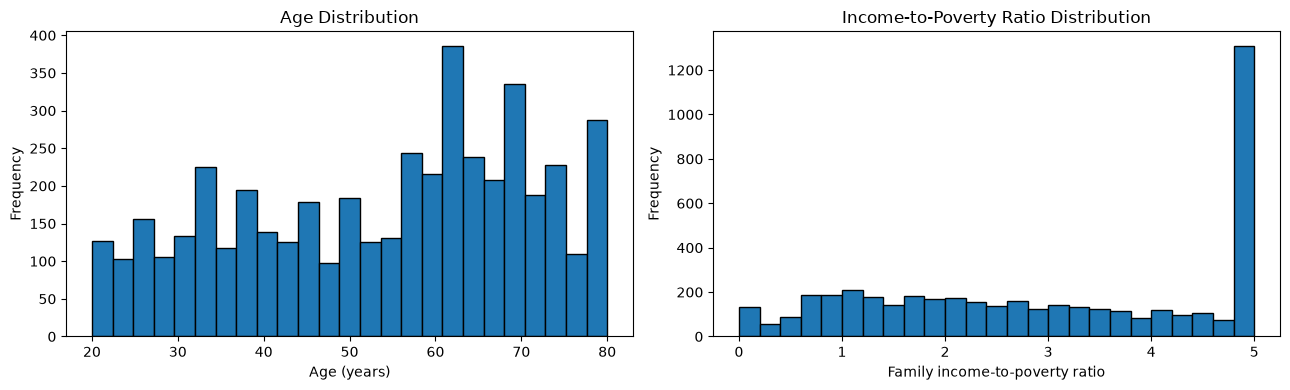

In [ ]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(
    model_cc["RIDAGEYR"],
    bins=25,
    edgecolor="black"
)
axes[0].set_title("Age Distribution")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Frequency")
axes[1].hist(
    model_cc["INDFMPIR"],
    bins=25,
    edgecolor="black"
)
axes[1].set_title("Income-to-Poverty Ratio Distribution")
axes[1].set_xlabel("Family income-to-poverty ratio")
axes[1].set_ylabel("Frequency")
plt.tight_layout()
plt.savefig(figures_dir / "age_income_distributions.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
def education_screening_summary(data):
    temp = data.copy()
    temp["weighted_positive"] = (
        temp["phq9_positive"] * temp["WTMEC2YR"]
    )
    summary = (
        temp.groupby("education_group", observed=True)
        .agg(
            Participants=("phq9_positive", "size"),
            Positive=("phq9_positive", "sum"),
            Total_Weight=("WTMEC2YR", "sum"),
            Positive_Weight=("weighted_positive", "sum")
        )
    )
    summary["Raw_Percentage"] = (
        summary["Positive"]
        / summary["Participants"]
        * 100
    )
    summary["Weighted_Percentage"] = (
        summary["Positive_Weight"]
        / summary["Total_Weight"]
        * 100
    )
    return summary.round(2)

original_summary = education_screening_summary(
    edu_analysis
)
complete_case_summary = education_screening_summary(
    model_cc
)
comparison_summary = pd.concat(
    {
        "Original_Sample": original_summary,
        "Complete_Case": complete_case_summary
    },
    axis=1
)
display(comparison_summary)

Original_Sample                        \
                             Participants Positive Total_Weight   
education_group                                                   
Less than 9th grade                   176       35   5551935.70   
9-11th grade                          372       61  12379935.59   
High school graduate/GED             1071      165  54209625.81   
Some college/AA degree               1622      245  63992474.60   
College graduate or above            1967      154  75236924.58   

                                                                              \
                          Positive_Weight Raw_Percentage Weighted_Percentage   
education_group                                                                
Less than 9th grade              981426.8          19.89               17.68   
9-11th grade                   1983655.74           16.4               16.02   
High school graduate/GED       7769398.64          15.41               14.33   
Some college/AA degree         8720212.53           15.1               13.63   
College graduate or above      6309591.86           7.83                8.39   

                          Complete_Case                                        \
                           Participants Positive Total_Weight Positive_Weight   
education_group                                                                 
Less than 9th grade                 142       28   4295153.46       746375.66   
9-11th grade                        318       54  10714882.97      1763992.63   
High school graduate/GED            921      149  45799053.65      7100345.52   
Some college/AA degree             1430      223  56299827.41      7838292.67   
College graduate or above          1773      139  67452511.54      5543127.58   

                                                              
                          Raw_Percentage Weighted_Percentage  
education_group                                               
Less than 9th grade                19.72               17.38  
9-11th grade                       16.98               16.46  
High school graduate/GED           16.18                15.5  
Some college/AA degree             15.59               13.92  
College graduate or above           7.84                8.22

### Complete Case Analysis: Final Assessment

The initial analytical sample included 5,208 participants with valid education information and complete PHQ-9 scores.

Among these participants, 624 (11.98%) had missing income-to-poverty ratio values, leaving 4,584 complete cases (88.02%).

Descriptive comparisons showed that income missingness varied across educational groups. However, age and sex distributions changed minimally after complete-case selection.

The weighted prevalence of positive PHQ-9 screening showed a similar decreasing pattern across educational levels in both samples. The largest absolute change was 1.17 percentage points in the high school graduate/GED group.

**Analytical decision:** The 5,208-participant sample will be retained for descriptive analyses not requiring income, while the 4,584-participant complete-case sample will be used for preliminary income-adjusted analyses.

Potential selection bias due to missing income cannot be ruled out. Sensitivity analyses will be considered in later phases.

In [ ]:
phq9_scores = edu_analysis["phq9_total"]
phq9_summary = phq9_scores.describe()
print("PHQ-9 descriptive statistics:")
display(phq9_summary.round(2))
print(
    "Interquartile Range (IQR):",
    round(
        phq9_scores.quantile(0.75)
        - phq9_scores.quantile(0.25),
        2
    )
)

PHQ-9 descriptive statistics:


count    5208.00
mean        4.04
std         4.68
min         0.00
25%         1.00
50%         2.00
75%         6.00
max        26.00
Name: phq9_total, dtype: float64

Interquartile Range (IQR): 5.0


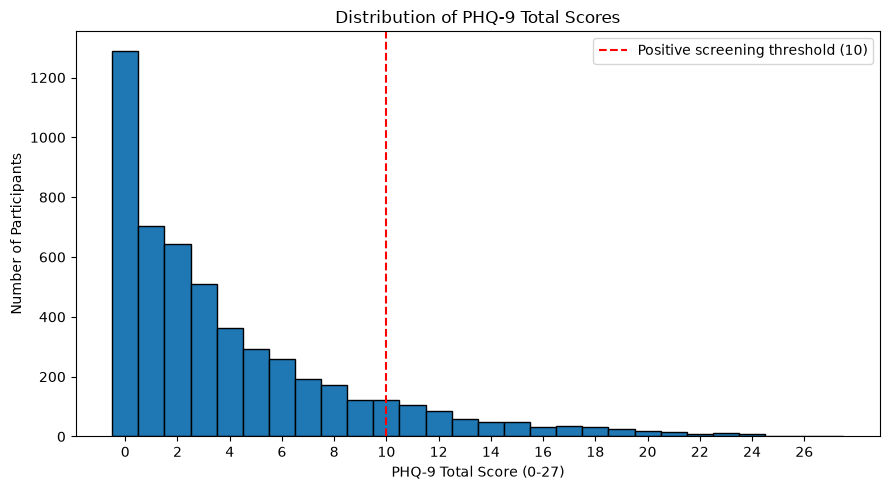

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(9, 5))
plt.hist(
    phq9_scores,
    bins=range(29),
    edgecolor="black",
    align="left"
)
plt.axvline(
    x=10,
    color="red",
    linestyle="--",
    label="Positive screening threshold (10)"
)
plt.title("Distribution of PHQ-9 Total Scores")
plt.xlabel("PHQ-9 Total Score (0-27)")
plt.ylabel("Number of Participants")
plt.xticks(range(0, 28, 2))
plt.legend()
plt.tight_layout()
plt.savefig(figures_dir / "phq9_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

### PHQ-9 Score Distribution: Interpretation

The PHQ-9 total score was analyzed among 5,208 participants with complete PHQ-9 responses and valid education data.

The mean score was 4.04 (SD = 4.68), while the median was 2. The first and third quartiles were 1 and 6, respectively, resulting in an interquartile range (IQR) of 5.

The histogram revealed a positively skewed distribution, with a high concentration of low scores, particularly zero.

The distribution was not approximately symmetric, suggesting that a simple normal distribution may not adequately describe the PHQ-9 scores.

A score of 10 or higher was used to define positive depression screening, rather than a clinical diagnosis.

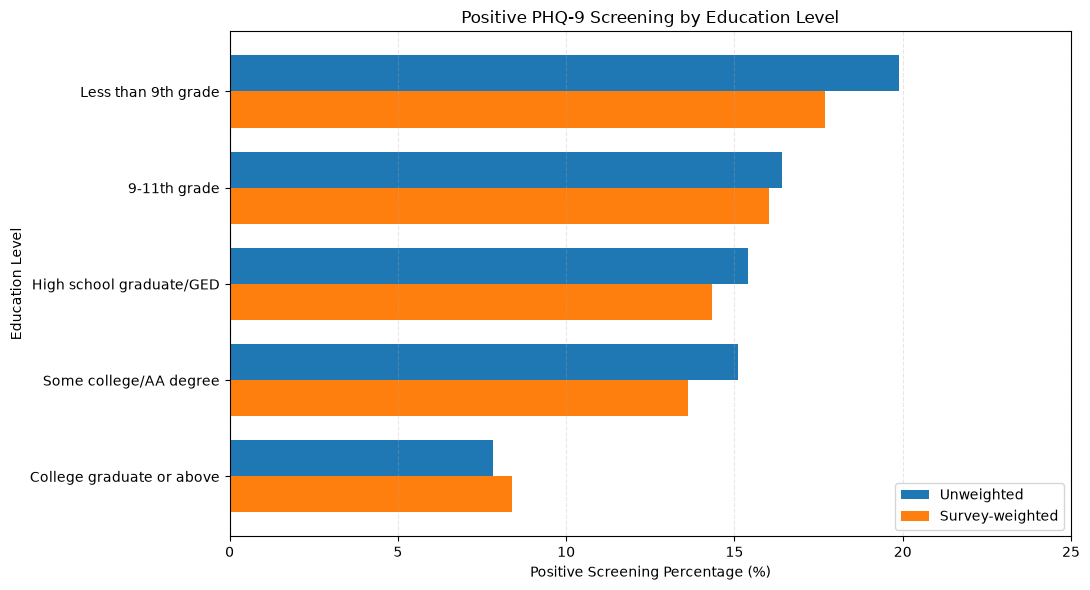

In [ ]:
plot_data = weighted_summary[
    ["Unweighted_Percentage", "Weighted_Percentage"]
].copy()
fig, ax = plt.subplots(figsize=(11, 6))
plot_data.plot(
    kind="barh",
    ax=ax,
    width=0.75
)
ax.invert_yaxis()
ax.set_title(
    "Positive PHQ-9 Screening by Education Level"
)
ax.set_xlabel(
    "Positive Screening Percentage (%)"
)
ax.set_ylabel("Education Level")
ax.set_xlim(0, 25)
ax.legend([
    "Unweighted",
    "Survey-weighted"
])
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)
plt.tight_layout()
from pathlib import Path
plt.savefig(figures_dir / "positive_screening_by_education.png", dpi=300, bbox_inches="tight")
plt.show()

### Weighted vs. Unweighted PHQ-9 Screening by Education

A comparison of weighted and unweighted positive PHQ-9 screening percentages revealed some differences across educational groups.

Survey weighting reduced the estimated screening prevalence in the first four educational groups, while slightly increasing the estimate among participants with a college degree or above.

Despite these differences, the overall decreasing pattern across educational levels remained consistent in both analyses.

These findings illustrate the importance of accounting for the NHANES sampling design when estimating population-level descriptive statistics.

The results are descriptive and do not establish statistical significance or a causal relationship.

### Association Between Education Level and Positive PHQ-9 Screening

,Participants,Positive,Total_Weight,Positive_Weight,Unweighted_Percentage,Weighted_Percentage
Sex,,,,,,
Male,2363,243,1.039645e+08,10212516.91,10.28,9.82
Female,2845,417,1.074064e+08,15551768.66,14.66,14.48


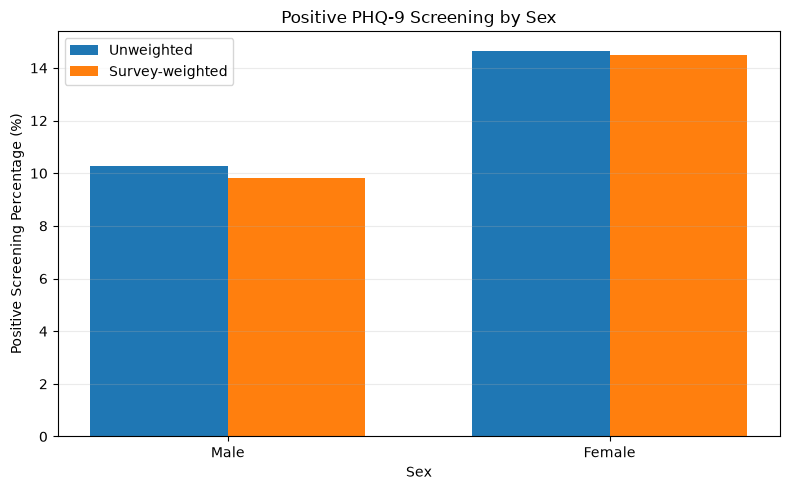

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

sex_plot = edu_analysis[["RIAGENDR", "phq9_positive", "WTMEC2YR"]].dropna().copy()
sex_plot["Sex"] = sex_plot["RIAGENDR"].map({1: "Male", 2: "Female"})
sex_plot["weighted_positive"] = sex_plot["phq9_positive"] * sex_plot["WTMEC2YR"]
sex_summary = (
    sex_plot.groupby("Sex", observed=True)
    .agg(
        Participants=("phq9_positive", "size"),
        Positive=("phq9_positive", "sum"),
        Total_Weight=("WTMEC2YR", "sum"),
        Positive_Weight=("weighted_positive", "sum")
    )
)
sex_summary["Unweighted_Percentage"] = (
    sex_summary["Positive"] / sex_summary["Participants"] * 100
)
sex_summary["Weighted_Percentage"] = (
    sex_summary["Positive_Weight"] / sex_summary["Total_Weight"] * 100
)
sex_summary = sex_summary.reindex(["Male", "Female"])
display(sex_summary.round(2))

x = np.arange(len(sex_summary))
width = 0.36
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(x - width / 2, sex_summary["Unweighted_Percentage"], width, label="Unweighted")
ax.bar(x + width / 2, sex_summary["Weighted_Percentage"], width, label="Survey-weighted")
ax.set_title("Positive PHQ-9 Screening by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Positive Screening Percentage (%)")
ax.set_xticks(x)
ax.set_xticklabels(sex_summary.index)
ax.legend()
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(figures_dir / "positive_screening_by_sex.png", dpi=300, bbox_inches="tight")
plt.show()

### Task 8: Data Visualization

Four figures were created to examine the distributions of the main variables and to compare positive PHQ-9 screening across educational and demographic groups.

**Figure 1: Age and Income Distributions**

The age and income-to-poverty ratio distributions were examined using histograms for the 4,584 complete-case participants. The distributions show variability in age and economic status. The income-to-poverty ratio has a concentration of observations at 5, reflecting the upper coding limit in the public NHANES data.

**Figure 2: PHQ-9 Score Distribution**

The histogram of PHQ-9 total scores was constructed using 5,208 participants with complete PHQ-9 responses and valid education information.

The distribution is positively skewed, with most participants reporting relatively low scores. A vertical dashed line at a score of 10 indicates the threshold for positive depression screening.

**Figure 3: Positive Depression Screening by Education**

A horizontal grouped bar chart compares unweighted and survey-weighted percentages of positive PHQ-9 screening across five educational attainment groups.

The observed percentage generally decreases with increasing education. The unweighted percentage was 19.89% among participants with less than a ninth-grade education and 7.83% among college graduates or above.

The corresponding survey-weighted percentages were 17.68% and 8.39%, respectively.

**Figure 4: Positive Depression Screening by Sex**

A grouped bar chart compares positive PHQ-9 screening percentages between males and females.

The unweighted percentage was 10.28% for males and 14.66% for females. The corresponding survey-weighted percentages were 9.82% and 14.48%.

Females showed a higher observed percentage of positive screening than males in both summaries.

**Visualization Decisions**

- Histograms were used for quantitative variables.
- Bar charts were used for categorical comparisons.
- Axes were labeled with appropriate quantities and units.
- Bar-chart percentage axes begin at zero to avoid misleading comparisons.
- Unweighted and survey-weighted summaries were clearly distinguished.
- No three-dimensional or unnecessary graphical effects were used.

These visualizations provide descriptive evidence only. They do not establish statistically significant differences or causal relationships. Inferential analyses will be performed in later phases.

In [ ]:
task9_table = weighted_summary[
    ["Participants", "Positive", "Unweighted_Percentage", "Weighted_Percentage"]
].copy()
task9_table.columns = [
    "Participants",
    "Positive Cases",
    "Unweighted (%)",
    "Weighted (%)"
]
display(task9_table.round(2))

lowest = task9_table.loc["Less than 9th grade"]
highest = task9_table.loc["College graduate or above"]

raw_difference = lowest["Unweighted (%)"] - highest["Unweighted (%)"]
weighted_difference = lowest["Weighted (%)"] - highest["Weighted (%)"]

print(f"Unweighted difference: {raw_difference:.2f} percentage points")
print(f"Weighted difference: {weighted_difference:.2f} percentage points")

,Participants,Positive Cases,Unweighted (%),Weighted (%)
education_group,,,,
Less than 9th grade,176,35,19.89,17.68
9-11th grade,372,61,16.4,16.02
High school graduate/GED,1071,165,15.41,14.33
Some college/AA degree,1622,245,15.1,13.63
College graduate or above,1967,154,7.83,8.39


Unweighted difference: 12.06 percentage points
Weighted difference: 9.29 percentage points


### Task 9: Preliminary Descriptive Comparison

A descriptive comparison was performed to examine the prevalence of positive PHQ-9 screening across five educational attainment levels among 5,208 adults.

The unweighted percentage of positive screening was highest among participants with less than a ninth-grade education (19.89%) and lowest among college graduates or above (7.83%).

The absolute difference between these two groups was 12.06 percentage points.

After applying NHANES sampling weights, the corresponding percentages were 17.68% and 8.39%, resulting in a difference of 9.29 percentage points.

Overall, both weighted and unweighted summaries showed a decreasing pattern in positive depression screening prevalence across higher levels of educational attainment.

However, these comparisons are purely descriptive. They do not establish statistical significance or demonstrate that higher educational attainment causes a reduction in depressive symptoms.

Differences in age, gender, and income distributions across educational groups may partly explain the observed pattern.

Statistical hypothesis testing and adjusted regression analyses will be conducted in later phases to investigate whether the observed association persists after accounting for these variables.

### Task 10: Final Statistical Research Question

#### Final Research Question

Does the prevalence of positive depression screening (PHQ-9 score ≥ 10) differ significantly across educational attainment levels among U.S. adults aged 20 years and older, and does this association remain statistically significant after adjusting for age, gender, and family income-to-poverty ratio?

#### Rationale for the Research Question

This research question was finalized after examining the structure, quality, and descriptive characteristics of the NHANES August 2021–August 2023 dataset.

The dataset is suitable for this investigation for several reasons:

1. Educational attainment is available as a categorical variable with five ordered levels.
2. Depressive symptoms are measured using the nine items of the PHQ-9 questionnaire, allowing the construction of a total score and a binary positive-screening indicator.
3. Age, gender, and family income-to-poverty ratio are available as potential adjustment variables.
4. NHANES provides sampling weights and survey design variables that support population-level statistical analysis when appropriately applied.
5. The analytical dataset contains 5,208 adults with complete PHQ-9 responses and valid educational attainment. A complete-case sample of 4,584 participants is available for the planned adjusted analysis.

#### Preliminary Descriptive Findings

Initial descriptive analysis showed differences in positive depression screening prevalence across educational attainment levels.

The unweighted prevalence ranged from 19.89% among participants with less than a ninth-grade education to 7.83% among college graduates or above.

The corresponding survey-weighted percentages were 17.68% and 8.39%.

These findings provide a descriptive motivation for the research question, but they do not establish statistical significance.

#### Planned Statistical Investigation

The relationship between education and positive depression screening will first be examined without adjustment.

Subsequent analyses will account for age, gender, and family income-to-poverty ratio to determine whether the educational association persists after adjustment.

Statistical inference and regression analyses will be conducted in later project phases. The complex NHANES survey design will be considered when interpreting inferential results.

#### Limitations

The NHANES data are cross-sectional and observational. Therefore, the analysis cannot establish a causal effect of education on depressive symptoms.

In addition, the PHQ-9 measures self-reported depressive symptoms and is not equivalent to a clinical diagnosis of depression.

Missing responses, complete-case selection, and the complex sampling design must also be considered when interpreting the findings.

#### Final Decision

The original research topic is retained because the available data contain the necessary outcome, explanatory variable, and adjustment variables.

The research question is sufficiently specific, measurable, and appropriate for descriptive and inferential statistical analysis in the remaining phases.

In [ ]:
merge_counts = merged_check["_merge"].value_counts()

a1_summary = pd.DataFrame({
    "Stage": [
        "DEMO_L.xpt",
        "DPQ_L.xpt",
        "Matched participants",
        "DEMO only",
        "DPQ only",
        "Final merged dataset"
    ],
    "Participants": [
        len(demo),
        len(dpq),
        int(merge_counts.get("both", 0)),
        int(merge_counts.get("left_only", 0)),
        int(merge_counts.get("right_only", 0)),
        len(merged)
    ]
})
display(a1_summary)

print("Merge key: SEQN")
print("DEMO duplicates:", demo["SEQN"].duplicated().sum())
print("DPQ duplicates:", dpq["SEQN"].duplicated().sum())
print("Merged duplicates:", merged["SEQN"].duplicated().sum())

assert demo["SEQN"].is_unique
assert dpq["SEQN"].is_unique
assert merged["SEQN"].is_unique
assert len(merged) == merge_counts.get("both", 0)

,Stage,Participants
0,DEMO_L.xpt,11933
1,DPQ_L.xpt,6337
2,Matched participants,6337
3,DEMO only,5596
4,DPQ only,0
5,Final merged dataset,6337


Merge key: SEQN
DEMO duplicates: 0
DPQ duplicates: 0
Merged duplicates: 0


### Task A1: NHANES Data Files and Merge Key

Two public-use data files from NHANES August 2021–August 2023 were used in this project:

- **DEMO_L.xpt:** Contains demographic information, including age, gender, educational attainment, income-to-poverty ratio, sampling weights, and survey design variables.
- **DPQ_L.xpt:** Contains responses to the depression screening questionnaire.

The common identifier between these files is `SEQN`, which uniquely identifies each NHANES participant.

The DEMO dataset contains 11,933 records, while the DPQ dataset contains 6,337 records.

Before merging, both datasets were checked for duplicate identifiers. No duplicate `SEQN` values were found.

An outer merge was initially performed to examine the matching structure. This identified:

- 6,337 participants present in both datasets.
- 5,596 participants present only in DEMO.
- No participants present only in DPQ.

The final dataset was constructed using an inner join on `SEQN`, with the `validate="one_to_one"` argument to enforce the expected relationship.

The resulting merged dataset contains 6,337 unique participants.

Participants without a matching DPQ record were not included in the merged dataset. This unmatched group includes individuals who were not eligible for the adult depression questionnaire.

After merging, the dataset was further restricted to participants aged 20 years and older, resulting in 6,064 adults before applying additional completeness criteria.

The successful one-to-one merge ensures that each participant appears only once and prevents duplication of observations during the analysis.

In [ ]:
survey_vars = ["WTINT2YR", "WTMEC2YR", "SDMVSTRA", "SDMVPSU"]
survey_audit = pd.DataFrame({
    "Missing": edu_analysis[survey_vars].isna().sum(),
    "Unique_Values": edu_analysis[survey_vars].nunique()
})
display(survey_audit)
print("Analytical participants:", len(edu_analysis))
print("Missing MEC weights:", edu_analysis["WTMEC2YR"].isna().sum())
print("Nonpositive MEC weights:", (edu_analysis["WTMEC2YR"] <= 0).sum())
print("\nMEC weight summary:")
display(edu_analysis["WTMEC2YR"].describe().round(2))
strata_count = edu_analysis["SDMVSTRA"].nunique()
psu_count = edu_analysis[["SDMVSTRA", "SDMVPSU"]].drop_duplicates().shape[0]
psu_per_stratum = edu_analysis.groupby("SDMVSTRA")["SDMVPSU"].nunique()
print("\nPseudo-strata:", strata_count)
print("Stratum-PSU combinations:", psu_count)
print("Two PSUs in every stratum:", (psu_per_stratum == 2).all())

,Missing,Unique_Values
WTINT2YR,0,4813
WTMEC2YR,0,4965
SDMVSTRA,0,15
SDMVPSU,0,2


Analytical participants: 5208
Missing MEC weights: 0
Nonpositive MEC weights: 0

MEC weight summary:


count      5208.00
mean      40585.81
std       29420.37
min        5424.59
25%       20216.17
50%       32038.52
75%       50373.81
max      227108.30
Name: WTMEC2YR, dtype: float64


Pseudo-strata: 15
Stratum-PSU combinations: 30
Two PSUs in every stratum: True


### Task A2: NHANES Sampling Weights and Survey Design

NHANES uses a complex, multistage probability sampling design involving stratification, clustering, and unequal selection probabilities.

The demographic dataset provides two main sampling weights:

- `WTINT2YR`: Full-sample interview weight.
- `WTMEC2YR`: Full-sample Mobile Examination Center (MEC) weight.

The PHQ-9 depression questionnaire was administered at the MEC. Therefore, `WTMEC2YR` was selected as the appropriate sampling weight for analyses involving depression screening.

Sampling weights account for unequal probabilities of selection, nonresponse adjustments, and population calibration. Consequently, different participants represent different numbers of people in the target population.

The survey design variables are:

- `SDMVSTRA`: Masked variance pseudo-stratum.
- `SDMVPSU`: Masked variance pseudo-primary sampling unit.

In the analytical sample of 5,208 participants, there were 15 pseudo-strata and 30 stratum-PSU combinations. Each stratum contained two pseudo-PSUs.

No missing or nonpositive MEC weights were observed in this sample.

The mean MEC sampling weight was 40,585.81, while the median was 32,038.52, indicating substantial variation in sampling weights.

Survey weights are used to estimate population-level quantities, while the stratification and clustering variables are also needed for appropriate variance estimation and statistical inference.

Applying weights alone does not account for the full complexity of the sampling design when calculating standard errors or performing hypothesis tests.

Furthermore, excluding participants with incomplete PHQ-9 responses or missing covariates may affect representativeness, even when the original sampling weights are used.

In this phase, sampling weights and design variables are identified and checked. Weighted and unweighted descriptive estimates are compared in Task A3, while appropriate design-based inference will be considered in later phases.

**Official documentation:**

- [NHANES Demographic Variables and Sample Weights](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm)
- [NHANES Depression Screener](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DPQ_L.htm)
- [NHANES Sampling Design Tutorial](https://wwwn.cdc.gov/nchs/nhanes/tutorials/SampleDesign.aspx)

In [ ]:
a3_unweighted = edu_analysis["phq9_positive"].mean() * 100
a3_weighted = (
    (edu_analysis["phq9_positive"] * edu_analysis["WTMEC2YR"]).sum()
    / edu_analysis["WTMEC2YR"].sum()
    * 100
)
a3_comparison = pd.DataFrame({
    "Method": ["Unweighted", "Survey-weighted"],
    "Positive Screening (%)": [a3_unweighted, a3_weighted]
})
display(a3_comparison.round(2))
difference = a3_weighted - a3_unweighted
print(f"Difference: {difference:.2f} percentage points")

,Method,Positive Screening (%)
0,Unweighted,12.67
1,Survey-weighted,12.19


Difference: -0.48 percentage points


### Task A3: Weighted vs. Unweighted Descriptive Estimates

Unweighted and survey-weighted estimates were compared to examine the effect of NHANES sampling weights on positive PHQ-9 screening prevalence.

Among 5,208 participants, the overall unweighted prevalence of positive PHQ-9 screening was 12.67%.

After applying the MEC sampling weights (`WTMEC2YR`), the estimated prevalence was 12.19%, a decrease of 0.48 percentage points.

The analysis also compared weighted and unweighted screening percentages across five educational attainment groups.

For participants with less than a ninth-grade education, the unweighted prevalence was 19.89%, compared with a weighted estimate of 17.68%.

For college graduates or above, the corresponding estimates were 7.83% and 8.39%.

These differences occur because NHANES participants have unequal sampling weights, reflecting differences in selection probabilities, nonresponse adjustments, and population calibration.

The overall descriptive pattern remained similar: higher educational attainment was generally associated with lower positive screening prevalence.

However, sampling weights alone do not account for stratification and clustering in variance estimation. In addition, missing data and sample exclusions may affect population representativeness.

The results are descriptive and do not establish statistical significance or causality.

In [ ]:
phq9_valid = analysis_base.loc[
    analysis_base["phq9_total"].notna()
]

sample_flow = pd.DataFrame({
    "Stage": [
        "Merged DEMO and DPQ",
        "Adults aged 20+",
        "Complete PHQ-9",
        "Valid education",
        "Complete-case sample"
    ],
    "Remaining": [
        len(merged),
        len(analysis_base),
        len(phq9_valid),
        len(edu_analysis),
        len(model_cc)
    ]
})

sample_flow["Excluded"] = (
    sample_flow["Remaining"].shift(1)
    - sample_flow["Remaining"]
).fillna(0).astype(int)

display(sample_flow)

print("Missing education among adults:",
      analysis_base["DMDEDUC2_clean"].isna().sum())

print("Missing education and incomplete PHQ-9:",
      (
          analysis_base["DMDEDUC2_clean"].isna()
          & analysis_base["phq9_total"].isna()
      ).sum())

print("Missing income in analytical sample:",
      edu_analysis["INDFMPIR"].isna().sum())

assert len(edu_analysis) == 5208
assert len(model_cc) == 4584
assert model_cc["SEQN"].is_unique

,Stage,Remaining,Excluded
0,Merged DEMO and DPQ,6337,0
1,Adults aged 20+,6064,273
2,Complete PHQ-9,5210,854
3,Valid education,5208,2
4,Complete-case sample,4584,624


Missing education among adults: 4
Missing education and incomplete PHQ-9: 2
Missing income in analytical sample: 624


### Task A4: Analytical Population and Inclusion/Exclusion Criteria

The target population of this study is U.S. civilian, noninstitutionalized adults aged 20 years and older, using NHANES August 2021–August 2023 data.

The unit of observation is an individual participant identified by `SEQN`.

#### Inclusion Criteria

Participants were included in the main analytical sample if they met the following criteria:

1. Were present in both DEMO and DPQ datasets.
2. Were aged 20 years or older.
3. Had valid responses to all nine PHQ-9 symptom questions.
4. Had valid educational attainment information.

For the planned adjusted analysis, participants were additionally required to have complete information on age, gender, family income-to-poverty ratio, and survey design variables.

#### Sample Selection

The merged DEMO and DPQ dataset contained 6,337 participants.

After excluding 273 participants younger than 20 years, 6,064 adults remained.

Among these adults, 854 participants had incomplete PHQ-9 responses, leaving 5,210 participants with valid PHQ-9 total scores.

Four adults had missing or invalid education information. Two of these participants had already been excluded due to incomplete PHQ-9 responses. Therefore, only two additional participants were excluded at this stage.

The resulting main analytical sample contained 5,208 participants.

Of these, 624 participants had missing income-to-poverty ratio information, leaving 4,584 complete cases for the planned adjusted analysis.

#### Final Analytical Samples

- **Main descriptive and unadjusted analytical sample:** 5,208 participants.
- **Complete-case sample for adjusted analysis:** 4,584 participants.

#### Missing Data and Generalizability

The complete-case approach ensures that the planned adjustment variables are available for each included participant. However, excluding participants with missing income information may introduce selection bias.

The main descriptive analyses retain participants with missing income when income is not required for the calculation.

Sampling weights and the complex NHANES survey design must be considered when making population-level inferences.

Because the study is observational and cross-sectional, the findings cannot establish a causal relationship between educational attainment and depressive symptoms.

The final sample selection is documented to ensure transparency and reproducibility.

In [ ]:
print("edu_analysis exists:", "edu_analysis" in globals())
print("Shape:", edu_analysis.shape)
print(edu_analysis[
    ["RIAGENDR", "phq9_positive", "WTMEC2YR"]
].head())

edu_analysis exists: True
Shape: (5208, 44)
   RIAGENDR  phq9_positive      WTMEC2YR
1       1.0              0  34084.721548
2       2.0              0  81196.277992
3       1.0              0  39988.452940
4       2.0              0  20776.254850
6       1.0              0  38984.867724


In [ ]:
print("Total participants:", len(edu_analysis))
print(
    "\nPHQ-9 positive count:",
    edu_analysis["phq9_positive"].sum()
)
print("\nPHQ-9 outcome distribution:")
display(
    edu_analysis["phq9_positive"]
    .value_counts(dropna=False)
    .sort_index()
)
print("\nGender distribution:")
display(
    edu_analysis["RIAGENDR"]
    .value_counts(dropna=False)
    .sort_index()
)
print("\nGender × PHQ-9 screening:")
display(
    pd.crosstab(
        edu_analysis["RIAGENDR"],
        edu_analysis["phq9_positive"],
        margins=True,
        dropna=False
    )
)

Total participants: 5208

PHQ-9 positive count: 660

PHQ-9 outcome distribution:


phq9_positive
0    4548
1     660
Name: count, dtype: Int64


Gender distribution:


RIAGENDR
1.0    2363
2.0    2845
Name: count, dtype: int64


Gender × PHQ-9 screening:


phq9_positive,0,1,All
RIAGENDR,,,
1.0,2120,243,2363
2.0,2428,417,2845
All,4548,660,5208


In [ ]:
from pathlib import Path

processed_dir = project_dir / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

datasets = {
    "Adult_Clean": analysis_base,
    "PHQ9_Analytical": edu_analysis,
    "Complete_Case": model_cc
}
for name, df in datasets.items():
    print(f"\n{name}")
    print("Shape:", df.shape)
    print("Unique participants:", df["SEQN"].nunique())
    print("Duplicate SEQN:", df["SEQN"].duplicated().sum())

assert len(analysis_base) == 6064
assert len(edu_analysis) == 5208
assert len(model_cc) == 4584
assert edu_analysis["phq9_positive"].notna().all()
assert model_cc[model_variables].notna().all().all()

analysis_base.to_csv(
    processed_dir / "nhanes_adult_clean.csv",
    index=False,
    encoding="utf-8-sig"
)
edu_analysis.to_csv(
    processed_dir / "nhanes_phq9_analytical.csv",
    index=False,
    encoding="utf-8-sig"
)
model_cc.to_csv(
    processed_dir / "nhanes_complete_case.csv",
    index=False,
    encoding="utf-8-sig"
)
print("\nAll datasets saved successfully.")


Adult_Clean
Shape: (6064, 42)
Unique participants: 6064
Duplicate SEQN: 0

PHQ9_Analytical
Shape: (5208, 44)
Unique participants: 5208
Duplicate SEQN: 0

Complete_Case
Shape: (4584, 44)
Unique participants: 4584
Duplicate SEQN: 0

All datasets saved successfully.


In [ ]:
import pandas as pd
from pathlib import Path

processed_dir = project_dir / "data" / "processed"
files = {
    "Adult_Clean": "nhanes_adult_clean.csv",
    "PHQ9_Analytical": "nhanes_phq9_analytical.csv",
    "Complete_Case": "nhanes_complete_case.csv"
}
expected_rows = {
    "Adult_Clean": 6064,
    "PHQ9_Analytical": 5208,
    "Complete_Case": 4584
}
for name, filename in files.items():
    df = pd.read_csv(processed_dir / filename)
    print(f"\n{'=' * 40}")
    print(name)
    print("Shape:", df.shape)
    print("Unique SEQN:", df["SEQN"].nunique())
    print("Duplicate SEQN:", df["SEQN"].duplicated().sum())
    print("Missing cells:", df.isna().sum().sum())
    assert len(df) == expected_rows[name]
    assert df["SEQN"].is_unique
print("\nAll exported datasets passed integrity checks.")


Adult_Clean
Shape: (6064, 42)
Unique SEQN: 6064
Duplicate SEQN: 0
Missing cells: 64054

PHQ9_Analytical
Shape: (5208, 44)
Unique SEQN: 5208
Duplicate SEQN: 0
Missing cells: 46912

Complete_Case
Shape: (4584, 44)
Unique SEQN: 4584
Duplicate SEQN: 0
Missing cells: 40738

All exported datasets passed integrity checks.
